In [1]:
%pip install -q pandas numpy scipy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

from scipy.stats import ks_2samp, chi2_contingency
import matplotlib.pyplot as plt

DATA_PATH = Path("data/raw/Telco-Customer-Churn.csv")
REPORTS_PATH = Path("reports")
REPORTS_PATH.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

baseline = pd.read_csv(DATA_PATH)

baseline["TotalCharges"] = pd.to_numeric(
    baseline["TotalCharges"], errors="coerce"
)

baseline.loc[
    baseline["TotalCharges"].isna()
    & (baseline["tenure"] == 0),
    "TotalCharges"
] = 0

baseline = baseline.drop_duplicates(
    subset=["customerID"]
).copy()

# Simulate a later batch for demonstration purposes.
current = baseline.sample(
    n=min(1500, len(baseline)),
    random_state=42
).copy()

current["MonthlyCharges"] = (
    current["MonthlyCharges"] * 1.08
).clip(upper=150)

print("Baseline rows:", len(baseline))
print("Monitoring batch rows:", len(current))
print("Current batch is simulated:", True)

Baseline rows: 7043
Monitoring batch rows: 1500
Current batch is simulated: True


In [5]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

drift_results = []

for feature in numeric_features:
    reference = baseline[feature].dropna()
    observed = current[feature].dropna()

    statistic, p_value = ks_2samp(
        reference,
        observed
    )

    drift_results.append({
        "Feature": feature,
        "Baseline_Mean": reference.mean(),
        "Current_Mean": observed.mean(),
        "KS_Statistic": statistic,
        "P_Value": p_value,
        "Drift_Flag": p_value < 0.05
    })

drift_df = pd.DataFrame(drift_results)

display(drift_df.round(4))

drift_df.to_csv(
    REPORTS_PATH / "data_drift_report.csv",
    index=False
)

,Feature,Baseline_Mean,Current_Mean,KS_Statistic,P_Value,Drift_Flag
0,tenure,32.3711,32.2553,0.0212,0.6249,False
1,MonthlyCharges,64.7617,69.4848,0.1485,0.0000,True
2,TotalCharges,2279.7343,2245.1315,0.0191,0.7470,False


In [6]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

categorical_results = []

for feature in categorical_features:
    reference_counts = (
        baseline[feature].fillna("Missing").value_counts()
    )
    current_counts = (
        current[feature].fillna("Missing").value_counts()
    )

    categories = sorted(
        set(reference_counts.index)
        | set(current_counts.index)
    )

    reference_values = [
        reference_counts.get(category, 0)
        for category in categories
    ]

    current_values = [
        current_counts.get(category, 0)
        for category in categories
    ]

    contingency = np.array([
        reference_values,
        current_values
    ])

    statistic, p_value, _, _ = chi2_contingency(
        contingency
    )

    categorical_results.append({
        "Feature": feature,
        "Chi_Square": statistic,
        "P_Value": p_value,
        "Drift_Flag": p_value < 0.05
    })

categorical_drift_df = pd.DataFrame(
    categorical_results
)

display(categorical_drift_df.round(4))

categorical_drift_df.to_csv(
    REPORTS_PATH / "categorical_drift_report.csv",
    index=False
)

,Feature,Chi_Square,P_Value,Drift_Flag
0,Contract,2.9939,0.2238,False
1,InternetService,0.1569,0.9245,False
2,PaymentMethod,0.2543,0.9684,False


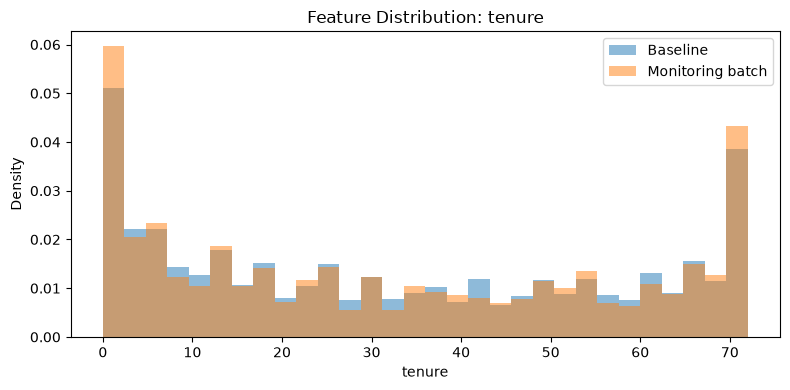

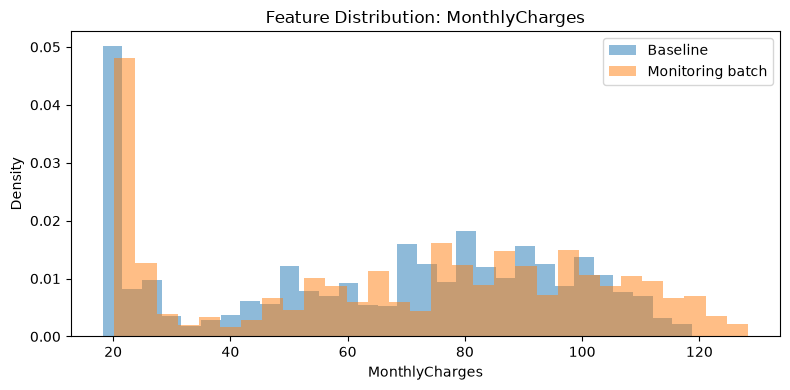

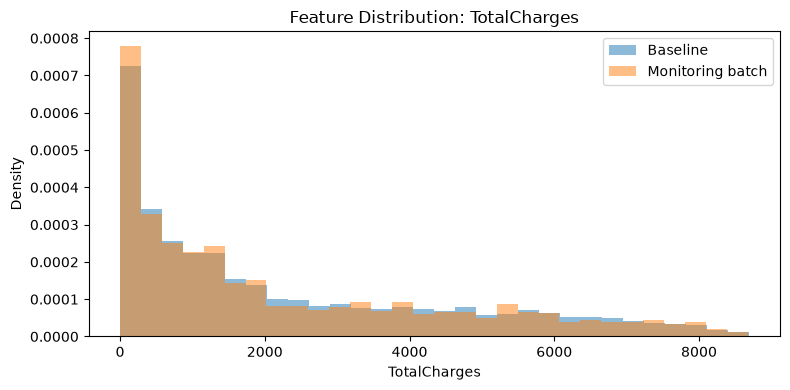

In [7]:
for feature in numeric_features:
    plt.figure(figsize=(8, 4))

    plt.hist(
        baseline[feature].dropna(),
        bins=30,
        alpha=0.5,
        label="Baseline",
        density=True
    )

    plt.hist(
        current[feature].dropna(),
        bins=30,
        alpha=0.5,
        label="Monitoring batch",
        density=True
    )

    plt.title(f"Feature Distribution: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [8]:
import joblib

MODEL_PATH = Path(
    "models/customer_churn_optimized_pipeline.joblib"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved model not found: {MODEL_PATH.resolve()}"
    )

model = joblib.load(MODEL_PATH)

feature_columns = list(
    model.named_steps["preprocessor"].feature_names_in_
)

def prepare_features(data):
    features = data.drop(
        columns=["Churn", "customerID"],
        errors="ignore"
    )

    return features[feature_columns]

baseline_X = prepare_features(baseline)
current_X = prepare_features(current)

baseline_probability = model.predict_proba(
    baseline_X
)[:, 1]

current_probability = model.predict_proba(
    current_X
)[:, 1]

print(
    "Baseline average predicted churn:",
    round(float(baseline_probability.mean()), 4)
)

print(
    "Monitoring batch average predicted churn:",
    round(float(current_probability.mean()), 4)
)

Baseline average predicted churn: 0.2661
Monitoring batch average predicted churn: 0.281


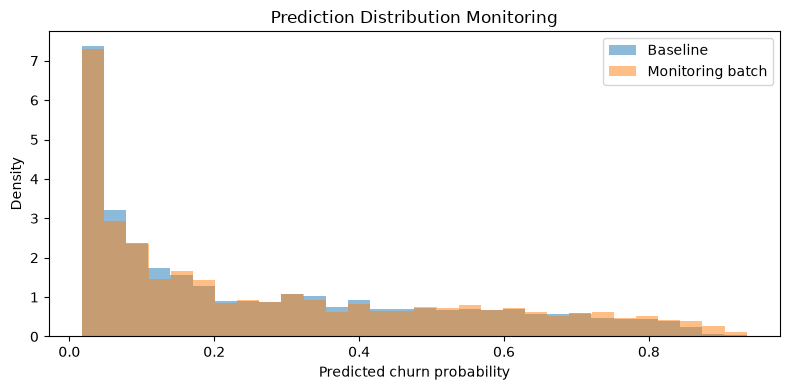

In [9]:
plt.figure(figsize=(8, 4))

plt.hist(
    baseline_probability,
    bins=30,
    alpha=0.5,
    density=True,
    label="Baseline"
)

plt.hist(
    current_probability,
    bins=30,
    alpha=0.5,
    density=True,
    label="Monitoring batch"
)

plt.xlabel("Predicted churn probability")
plt.ylabel("Density")
plt.title("Prediction Distribution Monitoring")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
summary = pd.DataFrame([
    {
        "Metric": "Baseline average predicted churn probability",
        "Value": float(baseline_probability.mean())
    },
    {
        "Metric": "Monitoring average predicted churn probability",
        "Value": float(current_probability.mean())
    },
    {
        "Metric": "Difference in average predicted probability",
        "Value": float(
            current_probability.mean()
            - baseline_probability.mean()
        )
    },
    {
        "Metric": "Numerical features flagged",
        "Value": int(drift_df["Drift_Flag"].sum())
    },
    {
        "Metric": "Categorical features flagged",
        "Value": int(categorical_drift_df["Drift_Flag"].sum())
    }
])

display(summary.round(4))

summary.to_csv(
    REPORTS_PATH / "model_monitoring_summary.csv",
    index=False
)

print("Step 9 reports saved successfully.")

,Metric,Value
0,Baseline average predicted churn probability,0.2661
1,Monitoring average predicted churn probability,0.2810
2,Difference in average predicted probability,0.0149
3,Numerical features flagged,1.0000
4,Categorical features flagged,0.0000


Step 9 reports saved successfully.
